# Módulo 2: predicción de casos de dengue con SimpleRNN

Primer modelo del checkpoint: con el clima y los casos de las últimas 26 semanas, pronostica los casos de las próximas 4 semanas. La LSTM se agrega después en este mismo notebook.

**Requerido por el enunciado, no visto en clase:** SimpleRNN con varias variables de entrada y salida de 4 semanas; seno y coseno de la semana para usar las fechas.

# 1. Importación librerías

In [1]:
import os
os.environ["TF_ENABLE_ONEDNN_OPTS"] = "0"   # para que los resultados se puedan repetir

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.layers import Dense, Input, SimpleRNN
from tensorflow.keras.models import Sequential, load_model
from tensorflow.keras.preprocessing.sequence import TimeseriesGenerator

tf.get_logger().setLevel("ERROR")   # oculta avisos internos de TensorFlow

# 2. Importación fuente de datos

In [2]:
# Usamos el archivo que dejó el EDA: casos reales, clima y log_casos
df = pd.read_csv("../data/processed/dengue_procesado.csv",
                 parse_dates=["fecha_inicio_semana"], index_col="fecha_inicio_semana")
print(df.shape)
print(df.index.min().date(), "a", df.index.max().date())
df[["casos_dengue", "log_casos", "lluvia_mm", "temp_max_c", "temp_min_c", "humedad_rel_pct"]].head()

(566, 25)
2014-02-23 a 2024-12-22


,casos_dengue,log_casos,lluvia_mm,temp_max_c,temp_min_c,humedad_rel_pct
fecha_inicio_semana,,,,,,
2014-02-23,96,4.574711,3.3,29.8,19.7,68.1
2014-03-02,75,4.330733,4.6,29.9,20.3,68.0
2014-03-09,94,4.553877,2.3,30.7,19.8,65.3
2014-03-16,71,4.276666,4.7,31.2,20.7,65.7
2014-03-23,95,4.564348,6.5,31.5,21.1,65.8


# 3. EDA + Preprocesado

El EDA completo está en `01_EDA.ipynb`. Lo que usamos de ahí:

- Los casos tienen brotes muy grandes, así que entrenamos con `log_casos`.
- El clima actúa con retraso. Una ventana de 26 semanas ya contiene el clima de hace 2, 4, 6 y 8 semanas; en la sección 7.1 revisamos si además conviene dar los lags como columnas.
- El enunciado pide usar las fechas. Convertimos la semana del año en seno y coseno para que la semana 52 quede pegada a la semana 1.

In [3]:
df["semana_sin"] = np.sin(2 * np.pi * df["semana_epi"] / 52)
df["semana_cos"] = np.cos(2 * np.pi * df["semana_epi"] / 52)

clima = ["lluvia_mm", "temp_max_c", "temp_min_c", "humedad_rel_pct"]
lags = [columna for columna in df.columns if "_lag" in columna]

columnas_base = ["log_casos"] + clima + ["semana_sin", "semana_cos"]
columnas_con_lags = columnas_base + lags
print(len(columnas_base), "variables base;", len(columnas_con_lags), "con lags")

7 variables base; 23 con lags


# 4. Train/Test

Es una serie de tiempo, así que el corte es temporal:

- **Test:** las últimas 104 semanas (2023-2024).
- **Validación:** las últimas 52 semanas de train (2022). Sirve para EarlyStopping y para elegir variables; el test no se usa para decidir nada.
- **Train:** todo lo anterior.

Cada ventana de entrada tiene 26 semanas y el objetivo son las 4 semanas siguientes. Las 4 semanas objetivo quedan siempre completas dentro de su propio grupo.

In [4]:
VENTANA = 26     # semanas de entrada
HORIZONTE = 4    # semanas a pronosticar
SEMANAS_TEST = 104
SEMANAS_VALIDACION = 52

n_total = len(df)
inicio_test = n_total - SEMANAS_TEST
inicio_validacion = inicio_test - SEMANAS_VALIDACION

print("Train: hasta", df.index[inicio_validacion - 1].date())
print("Validación:", df.index[inicio_validacion].date(), "a", df.index[inicio_test - 1].date())
print("Test:", df.index[inicio_test].date(), "a", df.index[-1].date())

Train: hasta 2021-12-26
Validación: 2022-01-02 a 2022-12-25
Test: 2023-01-01 a 2024-12-22


# 5. Escalado

In [5]:
# Los escaladores se ajustan solo con datos anteriores al test
escalador_y = MinMaxScaler().fit(df[["log_casos"]].values[:inicio_test])
y_escalado = escalador_y.transform(df[["log_casos"]].values).ravel()

# Objetivos: en la fila i están las 4 semanas que empiezan en i
objetivos = np.full((n_total, HORIZONTE), np.nan)
casos_reales = np.full((n_total, HORIZONTE), np.nan)
for i in range(n_total - HORIZONTE + 1):
    objetivos[i] = y_escalado[i:i + HORIZONTE]
    casos_reales[i] = df["casos_dengue"].values[i:i + HORIZONTE]

filas_validacion = np.arange(inicio_validacion, inicio_test - HORIZONTE + 1)
filas_test = np.arange(inicio_test, n_total - HORIZONTE + 1)


# Escala las columnas y crea los generadores de ventanas de train, validación y test
def preparar_datos(columnas):
    escalador_X = MinMaxScaler().fit(df[columnas].values[:inicio_test])
    X = escalador_X.transform(df[columnas].values)

    train = TimeseriesGenerator(X, objetivos, length=VENTANA, batch_size=16,
                                start_index=0, end_index=inicio_validacion - HORIZONTE)
    validacion = TimeseriesGenerator(X, objetivos, length=VENTANA, batch_size=64,
                                     start_index=inicio_validacion - VENTANA, end_index=inicio_test - HORIZONTE)
    test = TimeseriesGenerator(X, objetivos, length=VENTANA, batch_size=64,
                               start_index=inicio_test - VENTANA, end_index=n_total - HORIZONTE)
    return X, escalador_X, train, validacion, test


# Pasa una predicción escalada a casos reales: quita el escalado y el logaritmo
def a_casos(prediccion_escalada):
    log_casos = escalador_y.inverse_transform(prediccion_escalada.reshape(-1, 1))
    return np.expm1(log_casos).reshape(-1, HORIZONTE).clip(min=0)


print("Ventanas de validación:", len(filas_validacion), " Ventanas de test:", len(filas_test))

Ventanas de validación: 49  Ventanas de test: 101


# 6. Creación del modelo

In [6]:
def crear_modelo(n_variables):
    modelo = Sequential([
        Input(shape=(VENTANA, n_variables)),
        SimpleRNN(32),
        Dense(HORIZONTE),    # una salida por cada una de las 4 semanas
    ])
    modelo.compile(optimizer="adam", loss="mse")
    return modelo


crear_modelo(len(columnas_base)).summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn (SimpleRNN)          │ (None, 32)             │         1,280 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 4)              │           132 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,412 (5.52 KB)

 Trainable params: 1,412 (5.52 KB)

 Non-trainable params: 0 (0.00 B)

# 7. Entrenamiento

In [7]:
def entrenar(columnas, semilla):
    tf.keras.utils.set_random_seed(semilla)
    X, escalador_X, train, validacion, test = preparar_datos(columnas)
    modelo = crear_modelo(len(columnas))
    parada = EarlyStopping(monitor="val_loss", patience=20, restore_best_weights=True)
    historia = modelo.fit(train, validation_data=validacion, epochs=200, callbacks=[parada], verbose=0)
    return modelo, historia, X, escalador_X, validacion, test


def rmse(real, prediccion):
    return np.sqrt(np.mean((real - prediccion) ** 2))


def mae(real, prediccion):
    return np.mean(np.abs(real - prediccion))

## 7.1 ¿Conviene agregar los lags como columnas?

Comparamos solo con validación, repitiendo con 3 semillas porque una red cambia de una corrida a otra.

In [8]:
resultados = []
for nombre, columnas in [("Sin lags", columnas_base), ("Con lags", columnas_con_lags)]:
    for semilla in [101, 1, 2]:
        modelo, _, _, _, validacion, _ = entrenar(columnas, semilla)
        prediccion = a_casos(modelo.predict(validacion, verbose=0))
        resultados.append({"variables": nombre, "semilla": semilla,
                           "RMSE_validacion": rmse(casos_reales[filas_validacion], prediccion)})

comparacion = pd.DataFrame(resultados)
print(comparacion.pivot(index="semilla", columns="variables", values="RMSE_validacion").round(1))
print(comparacion.groupby("variables")["RMSE_validacion"].mean().round(1))

variables  Con lags  Sin lags
semilla                      
1              42.6      42.5
2              40.9      37.2
101            45.2      35.1
variables
Con lags    42.9
Sin lags    38.3
Name: RMSE_validacion, dtype: float64


Elegimos las variables con menor error promedio en validación. La ventana de 26 semanas ya contiene el clima de esos lags, y con 16 columnas más el modelo tiene más pesos que aprender con los mismos pocos datos.

## 7.2 Entrenamiento del modelo final

Variables elegidas: ['log_casos', 'lluvia_mm', 'temp_max_c', 'temp_min_c', 'humedad_rel_pct', 'semana_sin', 'semana_cos']


Épocas entrenadas: 77


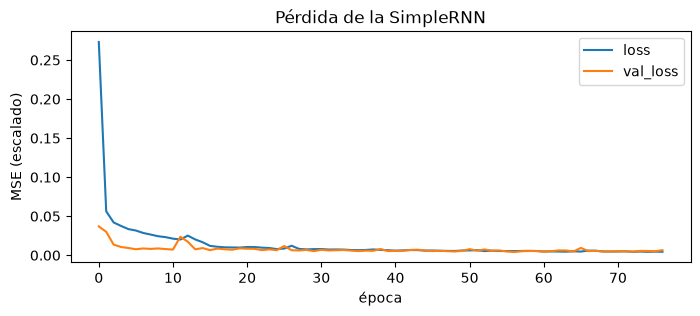

In [9]:
promedios = comparacion.groupby("variables")["RMSE_validacion"].mean()
columnas_finales = columnas_base if promedios["Sin lags"] <= promedios["Con lags"] else columnas_con_lags
print("Variables elegidas:", columnas_finales)

modelo_rnn, historia, X, escalador_X, gen_validacion, gen_test = entrenar(columnas_finales, semilla=101)
print("Épocas entrenadas:", len(historia.history["loss"]))

pd.DataFrame(historia.history).plot(figsize=(8, 3), title="Pérdida de la SimpleRNN")
plt.xlabel("época")
plt.ylabel("MSE (escalado)")
plt.show()

# 8. Evaluación y predicción

Medimos en **casos reales**, no en logaritmo, sobre las 101 ventanas completas del test. Comparamos contra:

- **Baseline estacional (lo pide el enunciado):** la misma semana del año anterior.
- **Persistencia (control extra):** las próximas 4 semanas repiten los casos de la última semana conocida. Es el pronóstico más simple posible, y sirve para saber si la red aporta algo más que copiar el último dato.

In [10]:
prediccion_test = a_casos(modelo_rnn.predict(gen_test, verbose=0))
real_test = casos_reales[filas_test]
casos = df["casos_dengue"].values

estacional = np.array([casos[i - 52:i - 52 + HORIZONTE] for i in filas_test])
persistencia = np.array([[casos[i - 1]] * HORIZONTE for i in filas_test])

tabla = pd.DataFrame({
    "RMSE": [rmse(real_test, p) for p in (prediccion_test, estacional, persistencia)],
    "MAE": [mae(real_test, p) for p in (prediccion_test, estacional, persistencia)],
}, index=["SimpleRNN", "Baseline estacional", "Persistencia"]).round(1)
print(tabla)

mejora = 100 * (1 - tabla.loc["SimpleRNN"] / tabla.loc["Baseline estacional"])
print("Mejora de la SimpleRNN sobre el baseline estacional (%):")
print(mejora.round(1))

                      RMSE    MAE
SimpleRNN            260.2  174.9
Baseline estacional  638.3  455.7
Persistencia         215.8  141.3
Mejora de la SimpleRNN sobre el baseline estacional (%):
RMSE    59.2
MAE     61.6
dtype: float64


In [11]:
# Error según qué tan lejos es el pronóstico
por_semana = pd.DataFrame({
    "RMSE_SimpleRNN": [rmse(real_test[:, h], prediccion_test[:, h]) for h in range(HORIZONTE)],
    "RMSE_persistencia": [rmse(real_test[:, h], persistencia[:, h]) for h in range(HORIZONTE)],
}, index=[f"semana +{h + 1}" for h in range(HORIZONTE)]).round(1)
por_semana

,RMSE_SimpleRNN,RMSE_persistencia
semana +1,229.2,129.2
semana +2,219.5,189.7
semana +3,338.7,236.3
semana +4,235.3,278.7


In [12]:
# Error por año del test, según la primera semana pronosticada
# El sesgo es real menos pronóstico: si es positivo, el pronóstico se queda corto
anios = df.index[filas_test].year
por_anio = pd.DataFrame([{
    "año": anio,
    "RMSE_SimpleRNN": rmse(real_test[anios == anio], prediccion_test[anios == anio]),
    "RMSE_estacional": rmse(real_test[anios == anio], estacional[anios == anio]),
    "RMSE_persistencia": rmse(real_test[anios == anio], persistencia[anios == anio]),
    "sesgo_SimpleRNN": (real_test[anios == anio] - prediccion_test[anios == anio]).mean(),
    "sesgo_estacional": (real_test[anios == anio] - estacional[anios == anio]).mean(),
} for anio in [2023, 2024]]).set_index("año").round(1)
por_anio

,RMSE_SimpleRNN,RMSE_estacional,RMSE_persistencia,sesgo_SimpleRNN,sesgo_estacional
año,,,,,
2023,301.0,718.2,252.0,146.1,470.8
2024,206.1,536.5,166.9,85.9,-14.6


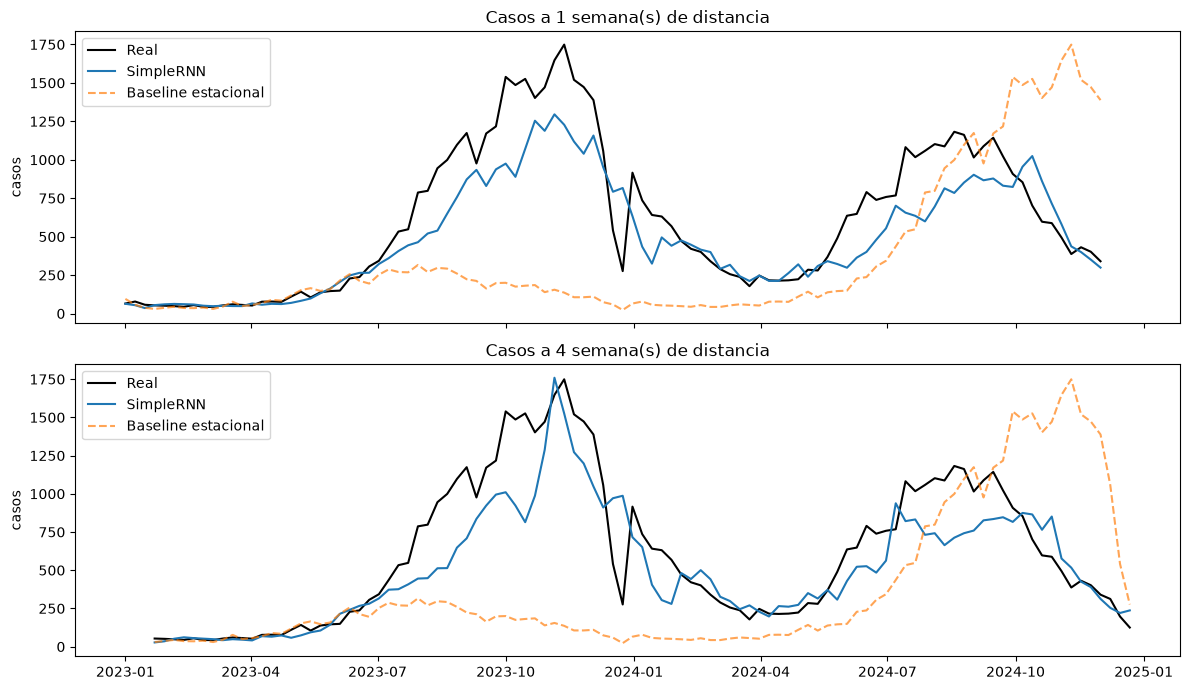

Semana del pico: 2023-11-12
Casos reales: 1749  Pronóstico a 1 semana: 1227


In [13]:
# Pronóstico contra lo real: a 1 semana y a 4 semanas
fechas = df.index

fig, ejes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
for eje, h in zip(ejes, [0, 3]):
    fechas_objetivo = fechas[filas_test + h]
    eje.plot(fechas_objetivo, real_test[:, h], label="Real", color="black")
    eje.plot(fechas_objetivo, prediccion_test[:, h], label="SimpleRNN")
    eje.plot(fechas_objetivo, estacional[:, h], label="Baseline estacional", linestyle="--", alpha=0.7)
    eje.set_title(f"Casos a {h + 1} semana(s) de distancia")
    eje.set_ylabel("casos")
    eje.legend()
plt.tight_layout()
plt.show()

# ¿Qué pasa en el pico del brote?
pico = real_test[:, 0].argmax()
print("Semana del pico:", fechas[filas_test[pico]].date())
print("Casos reales:", int(real_test[pico, 0]), " Pronóstico a 1 semana:", int(prediccion_test[pico, 0]))

## 8.1 ¿Qué tan estable es el resultado?

Repetimos el entrenamiento con 5 semillas. No se elige ninguna por su resultado en test: el modelo guardado es siempre el de la semilla 101.

In [14]:
semillas = []
for semilla in [101, 1, 2, 3, 4]:
    modelo, _, _, _, _, test = entrenar(columnas_finales, semilla)
    prediccion = a_casos(modelo.predict(test, verbose=0))
    semillas.append({"semilla": semilla, "RMSE": rmse(real_test, prediccion), "MAE": mae(real_test, prediccion)})

estabilidad = pd.DataFrame(semillas).set_index("semilla")
print(estabilidad.round(1))
print("Promedio:", estabilidad.mean().round(1).to_dict())
print("Rango de RMSE:", round(estabilidad["RMSE"].min(), 1), "a", round(estabilidad["RMSE"].max(), 1))

          RMSE    MAE
semilla              
101      260.2  174.9
1        225.6  148.6
2        234.0  157.1
3        319.8  195.7
4        241.0  154.3
Promedio: {'RMSE': 256.1, 'MAE': 166.1}
Rango de RMSE: 225.6 a 319.8


## 8.2 Guardar el modelo

In [15]:
os.makedirs("../models", exist_ok=True)
modelo_rnn.save("../models/rnn_simple.h5")

# Sin los escaladores y la lista de columnas, el modelo no se puede usar en la app
joblib.dump({"columnas": columnas_finales, "escalador_X": escalador_X, "escalador_y": escalador_y,
             "ventana": VENTANA, "horizonte": HORIZONTE}, "../models/rnn_simple_preprocesado.pkl")
print(os.listdir("../models"))

['rnn_simple.h5', 'rnn_simple_preprocesado.pkl']


## 8.3 Ejemplo de uso para la app

La ANN recibe `casos_pred_4sem`, que es la **suma** de las 4 semanas, así que la app debe sumar las 4 salidas de este modelo.

In [16]:
# Cargamos todo desde disco, como lo hará la app
modelo = load_model("../models/rnn_simple.h5", compile=False)
pre = joblib.load("../models/rnn_simple_preprocesado.pkl")

# Tomamos las 26 semanas anteriores a una fecha de ejemplo (la última que tiene sus 4 semanas reales)
fin = n_total - HORIZONTE
semanas = df[pre["columnas"]].iloc[fin - pre["ventana"]:fin].values
entrada = pre["escalador_X"].transform(semanas)[np.newaxis, ...]

salida = modelo.predict(entrada, verbose=0)
pronostico = np.expm1(pre["escalador_y"].inverse_transform(salida.reshape(-1, 1))).ravel().clip(min=0)

print("Pronóstico desde", df.index[fin].date(), ":", pronostico.round().astype(int))
print("Casos reales de esas semanas:", df["casos_dengue"].values[fin:fin + 4])
print("casos_pred_4sem para la ANN:", int(pronostico.sum()))

Pronóstico desde 2024-12-01 : [299 230 250 237]
Casos reales de esas semanas: [340 312 197 125]
casos_pred_4sem para la ANN: 1015


## 8.4 Conclusiones del primer modelo

- **Cumple la métrica del enunciado:** la SimpleRNN supera al baseline estacional, con RMSE de 260.2 contra 638.3 (59 % menos) y MAE de 174.9 contra 455.7 (62 % menos). El baseline falla por una razón distinta cada año: en 2023 usa 2022, un año bajo, y se queda corto por 471 casos por semana en promedio; en 2024 acierta el nivel promedio, pero no las semanas.
- **Todavía no supera a la persistencia:** copiar la última semana da RMSE de 215.8 y MAE de 141.3. La red solo gana a 4 semanas de distancia (RMSE de 235.3 contra 278.7). Este es el resultado que la LSTM debería mejorar.
- **Depende de la semilla:** con 5 semillas, el RMSE va de 225.6 a 319.8 (promedio 256.1). Para comparar con la LSTM hay que usar las mismas semillas, no una sola corrida.
- **Subestima los brotes:** en promedio se queda corta por 146 casos por semana en 2023 y 86 en 2024. En el pico (12 de noviembre de 2023) hubo 1,749 casos y pronosticó 1,227 a una semana de distancia; el máximo que vio en train y validación fue de 1,000. Esto importa porque la ANN decide las alertas con este pronóstico: si sale bajo, una alerta puede no activarse.
- **Variables:** sin lags dio mejor resultado en validación (RMSE de 38.3 contra 42.9), así que el modelo final no los usa como columnas. Esto cambia lo sugerido en el plan; la ventana de 26 semanas ya contiene ese clima.

**Siguiente paso:** agregar la LSTM en este notebook con el mismo split, las mismas semillas y las mismas métricas.